# PRCP-1016 – Heart Disease Prediction Using Machine Learning

**Domain:** Healthcare

## Objective
Analyze the supplied patient data and build machine-learning classification models to predict potential heart disease. Eight algorithms are evaluated, all eight are tuned using stratified cross-validation, and the final model is selected using validation performance before its untouched test-set performance is reported.


# 1. Import Libraries

### Definition
Import the packages required for data loading, exploratory analysis, preprocessing, machine learning, tuning, evaluation, and interpretation.

### Quality Controls
- Warnings are suppressed only to keep the notebook output clean.
- Hyperparameter searches use `n_jobs=1` for stable, warning-free execution across Jupyter environments.
- All preprocessing used for model selection is placed inside pipelines to prevent data leakage.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    cross_val_predict
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier

print("Libraries imported successfully!")

Libraries imported successfully!


# 2. Load Dataset

The project specification provides `values.csv` for patient features and `labels.csv` for the outcome. The dataset contains `patient_id` plus clinical predictors; `patient_id` is an identifier and is not used as a predictor.


In [2]:
# Load the dataset

# The notebook checks the standard project locations automatically.
candidate_dirs = [Path("dataset/data"), Path("dataset"), Path("data"), Path(".")]
data_dir = next((p for p in candidate_dirs if (p / "values.csv").exists() and (p / "labels.csv").exists()), None)

if data_dir is None:
    raise FileNotFoundError(
        "Could not find values.csv and labels.csv. Place them inside Heart_Disease/dataset/data/ and run again."
    )

values = pd.read_csv(data_dir / "values.csv")
labels = pd.read_csv(data_dir / "labels.csv")

print("Dataset folder:", data_dir)
print("Values shape  :", values.shape)
print("Labels shape  :", labels.shape)

display(values.head())
display(labels.head())


Dataset folder: dataset\data
Values shape  : (180, 14)
Labels shape  : (180, 2)


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


,patient_id,heart_disease_present
0,0z64un,0
1,ryoo3j,0
2,yt1s1x,1
3,l2xjde,1
4,oyt4ek,0


In [3]:
# Combine features and labels safely.
if "patient_id" in values.columns and "patient_id" in labels.columns:
    df = values.merge(
        labels,
        on="patient_id",
        how="inner",
        validate="one_to_one"
    )
else:
    if len(values) != len(labels):
        raise ValueError("values.csv and labels.csv have different row counts.")
    df = pd.concat(
        [values.reset_index(drop=True), labels.reset_index(drop=True)],
        axis=1
    )

print("Combined dataset shape:", df.shape)
display(df.head())

Combined dataset shape: (180, 15)


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


# 3. Domain Analysis and Data Understanding

The project describes clinical variables such as age, resting blood pressure, serum cholesterol, maximum heart rate, exercise-induced angina, chest-pain type, thalium test result, and other cardiovascular measurements.


In [4]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (180, 15)

Columns:
['patient_id', 'slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina', 'heart_disease_present']

Data types:


,Data Type
patient_id,str
slope_of_peak_exercise_st_segment,int64
thal,str
resting_blood_pressure,int64
chest_pain_type,int64
num_major_vessels,int64
fasting_blood_sugar_gt_120_mg_per_dl,int64
resting_ekg_results,int64
serum_cholesterol_mg_per_dl,int64
oldpeak_eq_st_depression,float64



Missing values:


,Missing Values
patient_id,0
slope_of_peak_exercise_st_segment,0
thal,0
resting_blood_pressure,0
chest_pain_type,0
num_major_vessels,0
fasting_blood_sugar_gt_120_mg_per_dl,0
resting_ekg_results,0
serum_cholesterol_mg_per_dl,0
oldpeak_eq_st_depression,0



Duplicate rows: 0


In [5]:
# Identify the target column robustly
possible_targets = [
    "heart_disease_present",
    "target",
    "label",
    "diagnosis",
    "has_disease",
    "disease"
]

target_column = next(
    (c for c in possible_targets if c in df.columns),
    None
)

if target_column is None:
    candidates = [c for c in labels.columns if c != "patient_id"]

    if len(candidates) == 1:
        target_column = candidates[0]
    else:
        raise ValueError("Could not identify a unique target column.")

print("Target column:", target_column)

target_summary = (
    df[target_column]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis(target_column)
    .reset_index(name="Count")
)

display(target_summary)

Target column: heart_disease_present


,heart_disease_present,Count
0,0,100
1,1,80


In [6]:
print("Statistical summary:")
display(df.describe(include="all").T)

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,180,180,0z64un,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slope_of_peak_exercise_st_segment,180.0,NaN,NaN,NaN,1.55,0.618838,1.0,1.0,1.0,2.0,3.0
thal,180,3,normal,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
resting_blood_pressure,180.0,NaN,NaN,NaN,131.311111,17.010443,94.0,120.0,130.0,140.0,180.0
chest_pain_type,180.0,NaN,NaN,NaN,3.155556,0.938454,1.0,3.0,3.0,4.0,4.0
num_major_vessels,180.0,NaN,NaN,NaN,0.694444,0.969347,0.0,0.0,0.0,1.0,3.0
fasting_blood_sugar_gt_120_mg_per_dl,180.0,NaN,NaN,NaN,0.161111,0.368659,0.0,0.0,0.0,0.0,1.0
resting_ekg_results,180.0,NaN,NaN,NaN,1.05,0.998742,0.0,0.0,2.0,2.0,2.0
serum_cholesterol_mg_per_dl,180.0,NaN,NaN,NaN,249.211111,52.717969,126.0,213.75,245.5,281.25,564.0
oldpeak_eq_st_depression,180.0,NaN,NaN,NaN,1.01,1.121357,0.0,0.0,0.8,1.6,6.2


# 4. Data Cleaning

### Key Decision
`patient_id` is removed because it is a unique/random identifier rather than a clinical predictor. The project specification explicitly describes it as an identifier. 

Duplicate rows are removed. Clinical outliers are **not automatically deleted**, because an unusual medical measurement can represent a genuine patient condition rather than a data error.


In [7]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)

print("Rows before duplicate removal:", before)
print("Rows after duplicate removal :", len(df))

Rows before duplicate removal: 180
Rows after duplicate removal : 180


In [8]:
y_raw = df[target_column].copy()

X_raw = df.drop(columns=[target_column], errors="ignore")
X_raw = X_raw.drop(columns=["patient_id"], errors="ignore")

# Convert target to binary numeric form.
if y_raw.dtype == "object" or str(y_raw.dtype).startswith("category"):
    target_values = y_raw.astype(str).str.strip().str.lower()

    mapping = {
        "0": 0, "1": 1,
        "no": 0, "yes": 1,
        "false": 0, "true": 1,
        "absent": 0, "present": 1,
        "negative": 0, "positive": 1
    }

    unique_values = set(target_values.dropna().unique())

    if unique_values.issubset(mapping.keys()):
        y = target_values.map(mapping)
    else:
        codes, unique_labels = pd.factorize(target_values)
        if len(unique_labels) != 2:
            raise ValueError("Target must contain exactly two classes.")
        y = pd.Series(codes, index=y_raw.index)
else:
    y = pd.to_numeric(y_raw, errors="coerce")

if y.isnull().any():
    raise ValueError("Target contains missing or invalid values.")

y = y.astype(int)

if sorted(y.unique()) != [0, 1]:
    raise ValueError("Target must contain binary classes 0 and 1.")

print("Feature shape:", X_raw.shape)
print("Target shape :", y.shape)
print("Target classes:", sorted(y.unique()))

target_summary = (
    y.value_counts()
    .sort_index()
    .rename_axis("heart_disease_present")
    .reset_index(name="Count")
)

display(target_summary)

Feature shape: (180, 13)
Target shape : (180,)
Target classes: [np.int64(0), np.int64(1)]


,heart_disease_present,Count
0,0,100
1,1,80


# 5. Exploratory Data Analysis (EDA)

EDA checks class balance, distributions, relationships with the target, correlations, and possible outliers.

**Important:** Outlier detection is used for understanding data quality. Values are not removed automatically because healthcare outliers may be clinically meaningful.


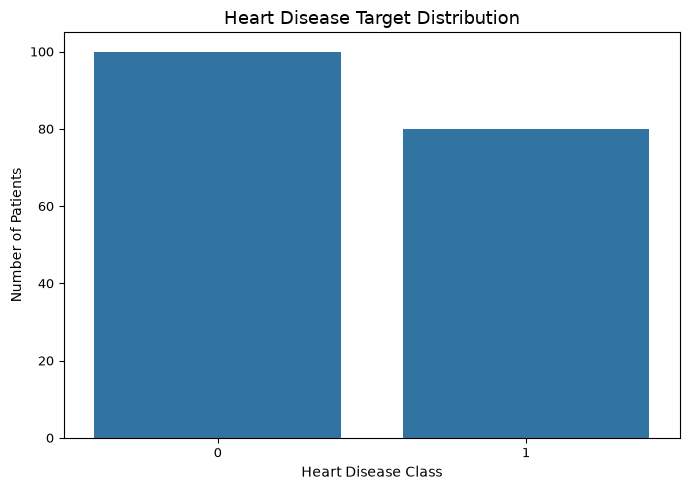

,heart_disease_present,Count,Percentage
0,0,100,55.56
1,1,80,44.44


In [9]:
# Target distribution with compact summary

target_summary = (
    y.value_counts()
    .sort_index()
    .rename_axis("heart_disease_present")
    .reset_index(name="Count")
)

target_summary["Percentage"] = (
    target_summary["Count"] / target_summary["Count"].sum() * 100
).round(2)

fig, ax = plt.subplots(figsize=(7, 5))

sns.countplot(x=y, ax=ax)

ax.set_title("Heart Disease Target Distribution", fontsize=13)
ax.set_xlabel("Heart Disease Class", fontsize=10)
ax.set_ylabel("Number of Patients", fontsize=10)
ax.tick_params(axis="both", labelsize=9)

plt.tight_layout()
plt.show()

display(target_summary)

Numerical features: ['slope_of_peak_exercise_st_segment', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina']
Categorical features: ['thal']


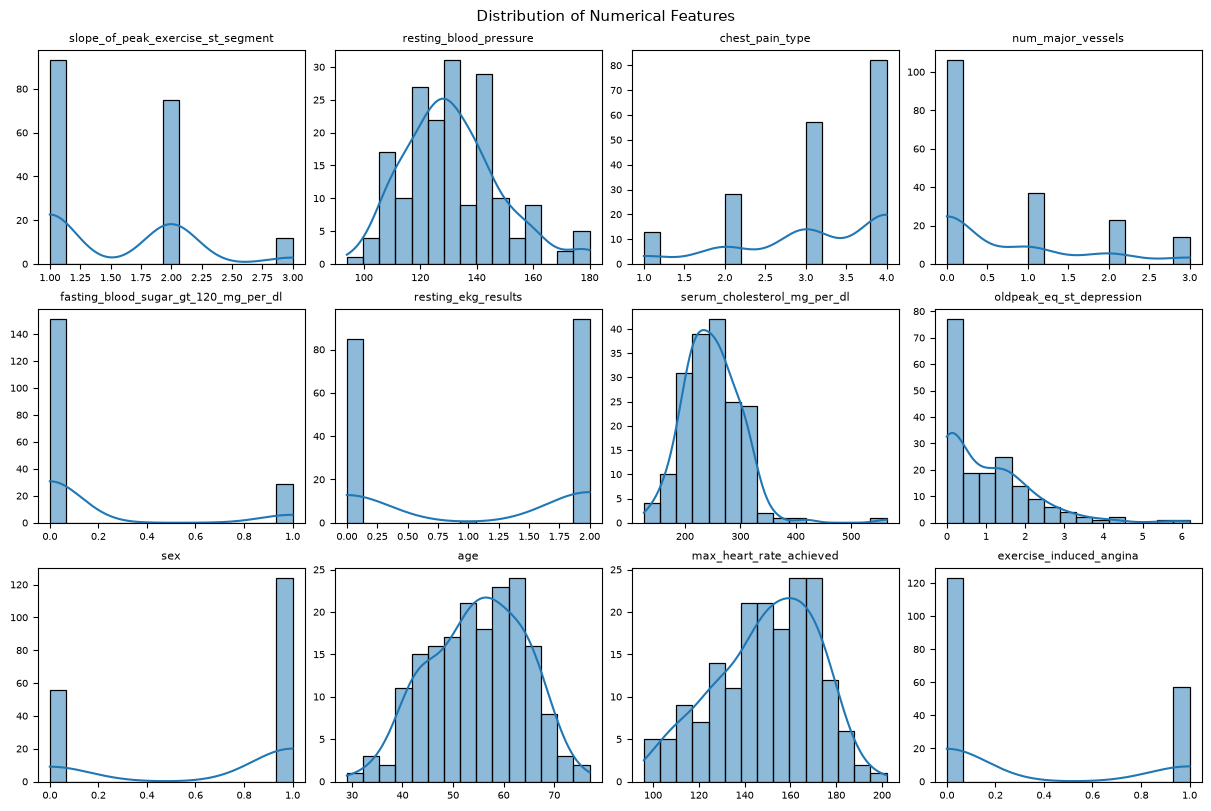

In [10]:
numeric_cols = X_raw.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_raw.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical features:", numeric_cols)
print("Categorical features:", categorical_cols)

# Numerical Feature Distributions - Neat Compact Layout

n_cols = 4
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, 8),
    constrained_layout=True
)

axes = np.array(axes).flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(
        X_raw[col],
        bins=15,
        kde=True,
        ax=axes[i]
    )
    
    axes[i].set_title(col, fontsize=8)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].tick_params(axis="both", labelsize=7)

for i in range(len(numeric_cols), len(axes)):
    axes[i].axis("off")

fig.suptitle("Distribution of Numerical Features", fontsize=11)

plt.show()


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
4,fasting_blood_sugar_gt_120_mg_per_dl,0.00,0.00,0.00,0.00,0.00,29
3,num_major_vessels,0.00,1.00,1.00,-1.50,2.50,14
2,chest_pain_type,3.00,4.00,1.00,1.50,5.50,13
1,resting_blood_pressure,120.00,140.00,20.00,90.00,170.00,6
7,oldpeak_eq_st_depression,0.00,1.60,1.60,-2.40,4.00,4
6,serum_cholesterol_mg_per_dl,213.75,281.25,67.50,112.50,382.50,2
0,slope_of_peak_exercise_st_segment,1.00,2.00,1.00,-0.50,3.50,0
5,resting_ekg_results,0.00,2.00,2.00,-3.00,5.00,0
8,sex,0.00,1.00,1.00,-1.50,2.50,0
9,age,48.00,62.00,14.00,27.00,83.00,0


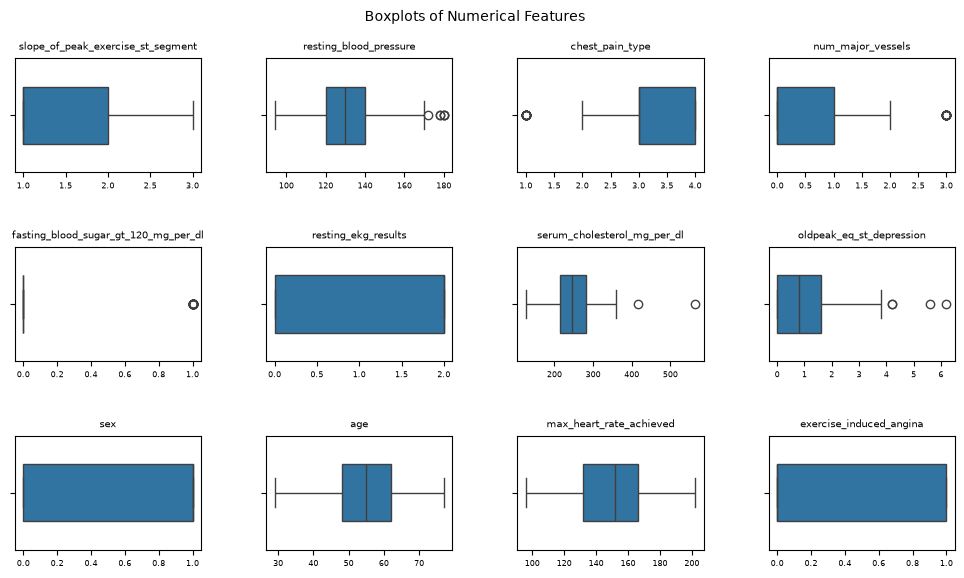

In [11]:
# Outlier summary using the IQR rule

outlier_rows = []

for col in numeric_cols:
    q1 = X_raw[col].quantile(0.25)
    q3 = X_raw[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((X_raw[col] < lower) | (X_raw[col] > upper)).sum()

    outlier_rows.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": int(count)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values(
    "Outlier Count", ascending=False
)

display(outlier_summary.round(2))


# Direct compact boxplots: 4 boxes in one row

n_cols = 4
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(10, 6)
)

axes = np.array(axes).flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        x=X_raw[col],
        ax=axes[i],
        width=0.5
    )
    axes[i].set_title(col, fontsize=7)
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", labelsize=6)
    axes[i].tick_params(axis="y", labelsize=6)

for i in range(len(numeric_cols), len(axes)):
    axes[i].axis("off")

fig.suptitle("Boxplots of Numerical Features", fontsize=10)
plt.subplots_adjust(
    left=0.04,
    right=0.98,
    top=0.90,
    bottom=0.08,
    wspace=0.35,
    hspace=0.65
)

plt.show()

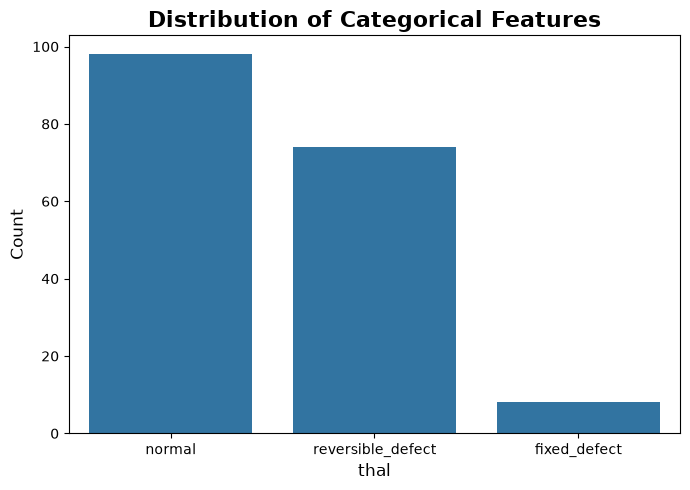

In [12]:
# Categorical feature distributions

for col in categorical_cols:
    plt.figure(figsize=(7,5))
    sns.countplot(data=X_raw, x=col)

    plt.title(
        "Distribution of Categorical Features",
        fontsize=16,
        fontweight="bold"
    )
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Count", fontsize=12)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)

    plt.tight_layout()
    plt.show()

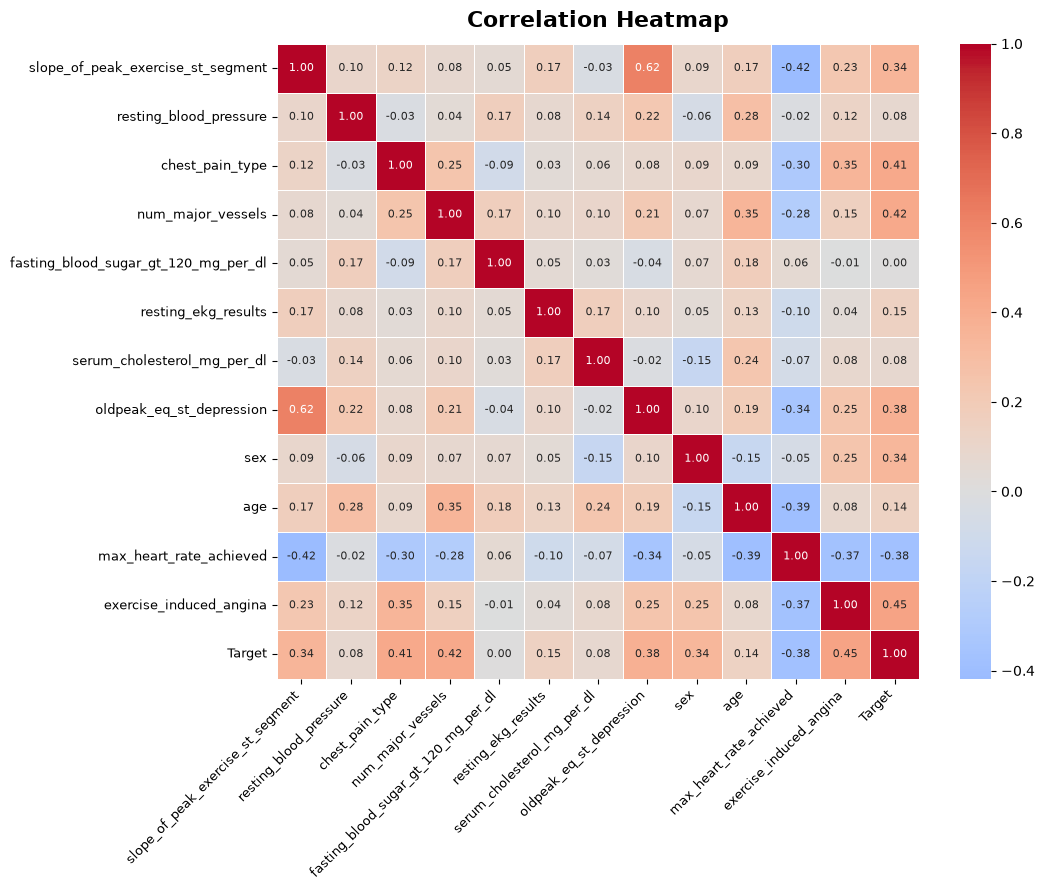

In [13]:
# Correlation among numeric variables and the target

eda_numeric = X_raw.select_dtypes(include=np.number).copy()
eda_numeric["Target"] = y.values

plt.figure(figsize=(11, 9))

sns.heatmap(
    eda_numeric.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    annot_kws={"size": 8},
    linewidths=0.5
)

plt.title(
    "Correlation Heatmap",
    fontsize=16,
    fontweight="bold",
    pad=12
)

plt.xticks(fontsize=9, rotation=45, ha="right")
plt.yticks(fontsize=9, rotation=0)

plt.tight_layout()
plt.show()

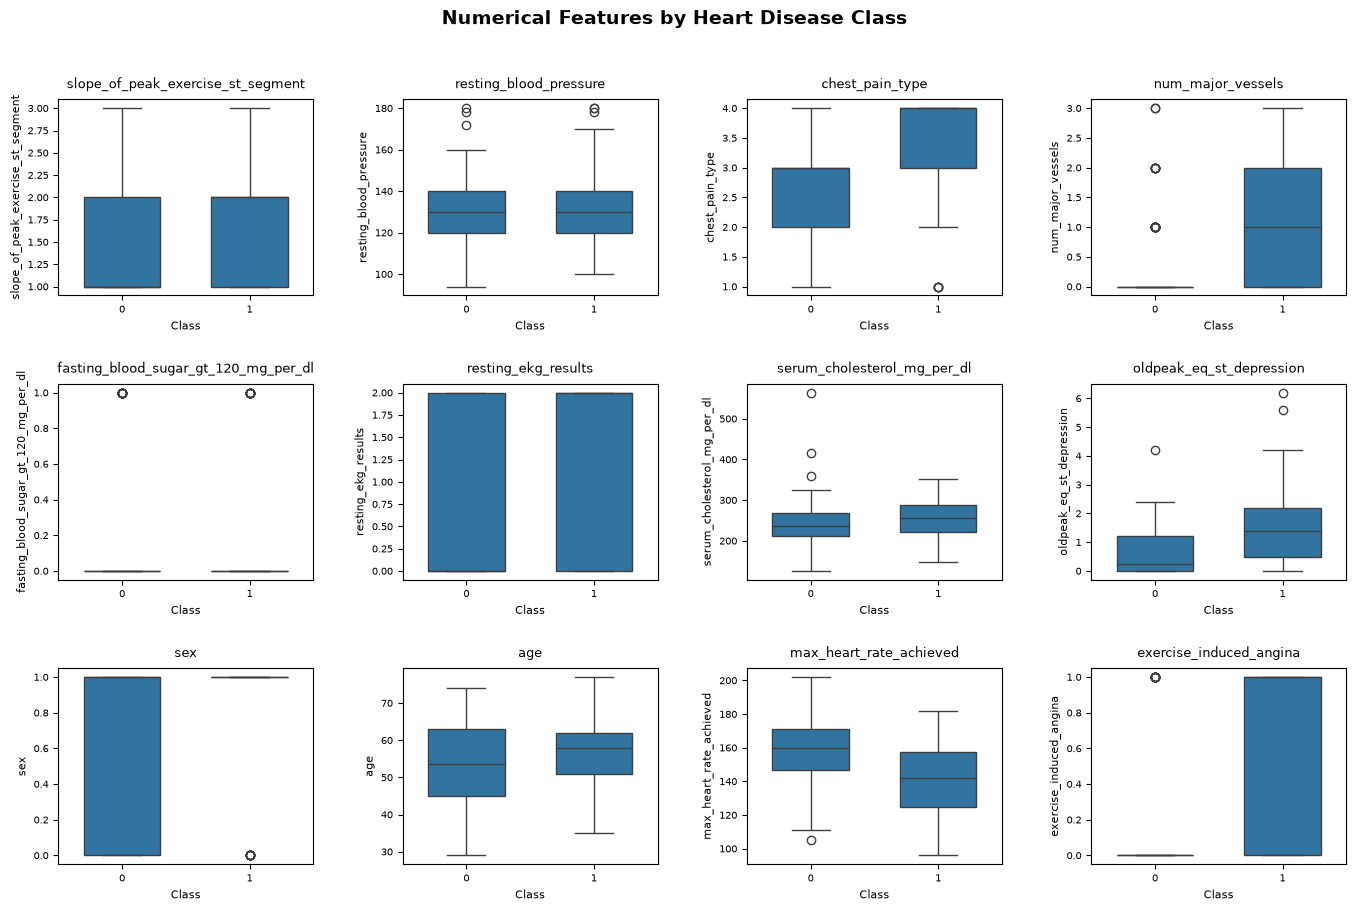

In [14]:
# Numerical Features by Target Class

n_cols = 4
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(14, 9)
)

axes = np.array(axes).flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(x=y, y=X_raw[col], ax=axes[i], width=0.6)

    axes[i].set_title(col, fontsize=9, pad=8)
    axes[i].set_xlabel("Class", fontsize=8)
    axes[i].set_ylabel(col, fontsize=8)

    axes[i].tick_params(axis="both", labelsize=7)

for i in range(len(numeric_cols), len(axes)):
    axes[i].axis("off")

fig.suptitle(
    "Numerical Features by Heart Disease Class",
    fontsize=14,
    fontweight="bold",
    y=1.02
)

plt.subplots_adjust(
    left=0.06,
    right=0.98,
    top=0.92,
    bottom=0.07,
    wspace=0.35,
    hspace=0.45
)

plt.show()

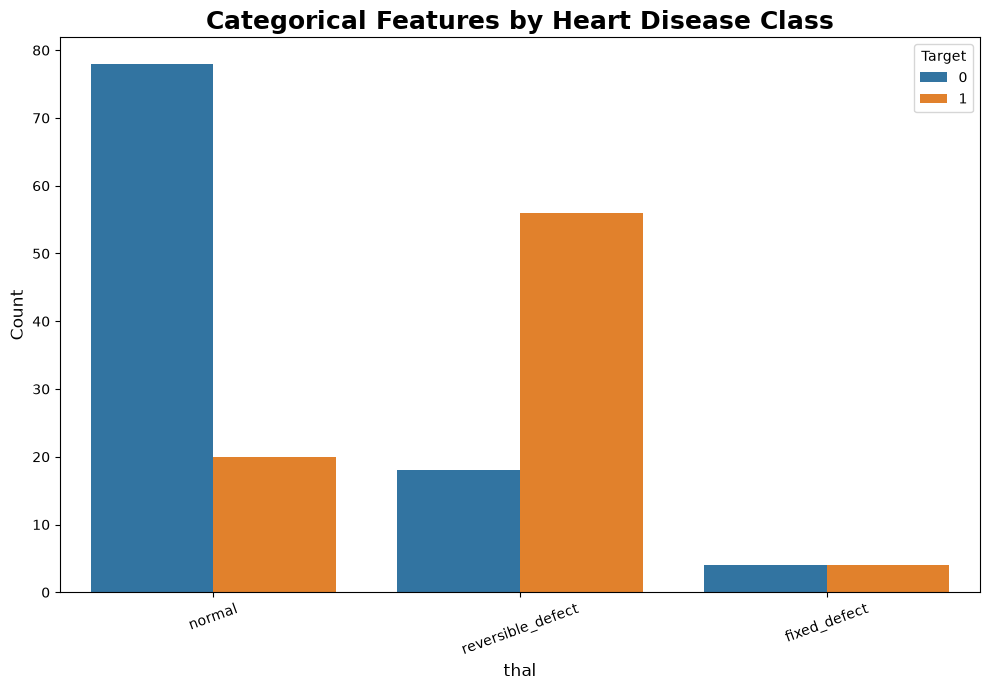

In [15]:
# Categorical features by Target Class

if categorical_cols:
    fig, ax = plt.subplots(figsize=(10, 7))

    plot_data = pd.DataFrame({
        "Feature": X_raw[categorical_cols[0]],
        "Target": y
    })

    sns.countplot(
        data=plot_data,
        x="Feature",
        hue="Target",
        ax=ax
    )

    ax.set_title(
        "Categorical Features by Heart Disease Class",
        fontsize=18,
        fontweight="bold"
    )
    ax.set_xlabel(categorical_cols[0], fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    ax.tick_params(axis="x", labelrotation=20, labelsize=10)
    ax.tick_params(axis="y", labelsize=10)

    plt.tight_layout()
    plt.show()

### EDA Insights

- The target distribution shows whether the classes are balanced or imbalanced.
- Numerical distributions help identify scale differences and possible outliers.
- Categorical plots show how clinical categories differ across the outcome classes.
- Correlation is used as an exploratory tool, not as the only feature-selection method.
- Medical outliers are retained unless there is clear evidence that they are data-entry errors.


# 6. Train-Test Split and Leakage-Safe Preprocessing

The data is split before model fitting. Stratification keeps the target-class proportions similar in training and testing sets.

All imputing, encoding, and scaling used during cross-validation are placed inside a `Pipeline`/`ColumnTransformer`. This prevents information from the validation folds from leaking into the training folds.


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Version-compatible OneHotEncoder.
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

transformers = [
    ("numeric", numeric_pipeline, numeric_features)
]

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Training rows: 144
Testing rows : 36
Numeric features: ['slope_of_peak_exercise_st_segment', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina']
Categorical features: ['thal']


# 7. Baseline Model Building

Eight classification algorithms are evaluated:

1. Logistic Regression
2. K-Nearest Neighbors
3. Support Vector Machine
4. Decision Tree
5. Random Forest
6. Gradient Boosting
7. XGBoost
8. Artificial Neural Network

The same stratified 5-fold cross-validation strategy is used to compare models fairly.


In [17]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Support Vector Machine": SVC(
        probability=True,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,
        verbosity=0
    ),
    "Artificial Neural Network": MLPClassifier(
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.15,
        random_state=42
    )
}

def make_pipeline(model):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

def evaluate_pipeline(name, model):
    pipe = make_pipeline(model)

    cv_result = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    pipe.fit(X_train, y_train)

    test_pred = pipe.predict(X_test)
    test_prob = pipe.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "CV Accuracy": cv_result["test_accuracy"].mean(),
        "CV Precision": cv_result["test_precision"].mean(),
        "CV Recall": cv_result["test_recall"].mean(),
        "CV F1": cv_result["test_f1"].mean(),
        "CV F1 Std": cv_result["test_f1"].std(),
        "CV ROC-AUC": cv_result["test_roc_auc"].mean(),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Test Precision": precision_score(y_test, test_pred, zero_division=0),
        "Test Recall": recall_score(y_test, test_pred, zero_division=0),
        "Test F1": f1_score(y_test, test_pred, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, test_prob)
    }, pipe

baseline_rows = []
baseline_pipelines = {}

for name, model in models.items():
    row, pipe = evaluate_pipeline(name, model)
    baseline_rows.append(row)
    baseline_pipelines[name] = pipe

baseline_results = pd.DataFrame(baseline_rows).sort_values(
    ["CV F1", "CV ROC-AUC", "CV Accuracy"],
    ascending=False
).reset_index(drop=True)

display(baseline_results.round(4))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV F1 Std,CV ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Support Vector Machine,0.8333,0.8305,0.7973,0.8063,0.0625,0.8868,0.8333,0.7778,0.8750,0.8235,0.9500
1,Random Forest,0.8333,0.8407,0.7814,0.8027,0.0962,0.8891,0.8889,0.8333,0.9375,0.8824,0.9484
2,Logistic Regression,0.8125,0.8200,0.7511,0.7703,0.0851,0.8815,0.8056,0.7647,0.8125,0.7879,0.9406
3,XGBoost,0.7917,0.7737,0.7662,0.7603,0.0558,0.8792,0.8333,0.7500,0.9375,0.8333,0.9344
4,K-Nearest Neighbors,0.7847,0.7765,0.7338,0.7467,0.0567,0.8499,0.8889,0.8750,0.8750,0.8750,0.9141
5,Gradient Boosting,0.7569,0.7184,0.7662,0.7349,0.0368,0.8640,0.9167,0.8421,1.0000,0.9143,0.9562
6,Decision Tree,0.7569,0.7206,0.7359,0.7221,0.0798,0.7557,0.7778,0.7857,0.6875,0.7333,0.7687
7,Artificial Neural Network,0.6736,0.6094,0.7186,0.6579,0.0739,0.7379,0.8333,0.7500,0.9375,0.8333,0.8938


In [18]:
# Same eight model definitions retained for the tuning section.
tuning_models = models.copy()


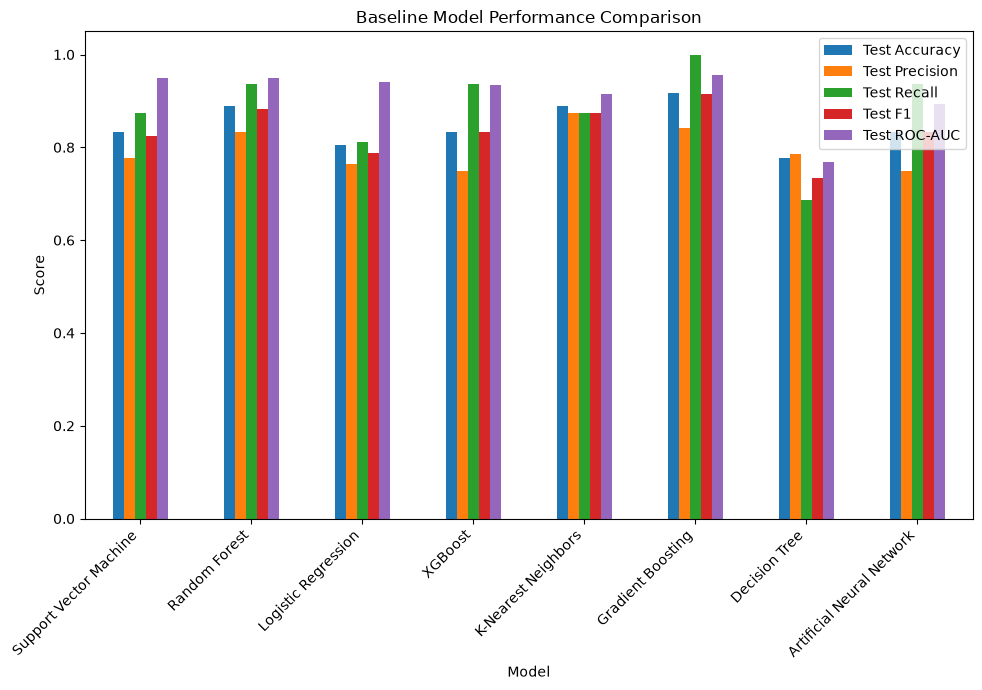

In [19]:
# Baseline visual comparison.
baseline_plot = baseline_results.set_index("Model")[
    ["Test Accuracy", "Test Precision", "Test Recall", "Test F1", "Test ROC-AUC"]
]

ax = baseline_plot.plot(kind="bar", figsize=(10,7))
ax.set_title("Baseline Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 8. Hyperparameter Tuning – All Eight Models

All eight classification models are tuned using stratified 3-fold cross-validation. The test set remains untouched until final evaluation.

The parameter grids are kept focused enough for reliable execution in Jupyter while still testing meaningful model configurations.


### Tuning Setup

Each model is tuned separately using Stratified 3-Fold Cross-Validation. The test set is used only for final evaluation of each tuned model.

**Speed setting:** 3-fold stratified cross-validation is used to reduce runtime while keeping validation stratified and reproducible. All eight models and all eight tuning sections are retained.


## 8.1 Logistic Regression


In [20]:
logistic_params = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "model__solver": ["liblinear", "lbfgs"],
    "model__class_weight": [None, "balanced"]
}

search_logistic = GridSearchCV(
    estimator=make_pipeline(
        LogisticRegression(max_iter=3000, random_state=42)
    ),
    param_grid=logistic_params,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True
)

search_logistic.fit(X_train, y_train)
logistic_best = search_logistic.best_estimator_
logistic_pred = logistic_best.predict(X_test)
logistic_prob = logistic_best.predict_proba(X_test)[:, 1]

print("Best Parameters:", search_logistic.best_params_)
print("Best CV Accuracy:", round(search_logistic.best_score_, 4))
print("Test Accuracy:", round(accuracy_score(y_test, logistic_pred), 4))
print("Test F1:", round(f1_score(y_test, logistic_pred, zero_division=0), 4))

Best Parameters: {'model__C': 0.001, 'model__class_weight': None, 'model__solver': 'liblinear'}
Best CV Accuracy: 0.8542
Test Accuracy: 0.8333
Test F1: 0.8125


## 8.2 K-Nearest Neighbors


In [21]:
knn_params = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 13, 15, 17, 19, 21],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

search_knn = GridSearchCV(
    estimator=make_pipeline(KNeighborsClassifier()),
    param_grid=knn_params,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True
)

search_knn.fit(X_train, y_train)
knn_best = search_knn.best_estimator_
knn_pred = knn_best.predict(X_test)
knn_prob = knn_best.predict_proba(X_test)[:, 1]

print("Best Parameters:", search_knn.best_params_)
print("Best CV Accuracy:", round(search_knn.best_score_, 4))
print("Test Accuracy:", round(accuracy_score(y_test, knn_pred), 4))
print("Test F1:", round(f1_score(y_test, knn_pred, zero_division=0), 4))

Best Parameters: {'model__n_neighbors': 19, 'model__p': 2, 'model__weights': 'uniform'}
Best CV Accuracy: 0.8542
Test Accuracy: 0.8611
Test F1: 0.8387


## 8.3 Support Vector Machine


In [22]:
svm_params = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}

search_svm = GridSearchCV(
    estimator=make_pipeline(
        SVC(probability=True, random_state=42)
    ),
    param_grid=svm_params,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True
)

search_svm.fit(X_train, y_train)
svm_best = search_svm.best_estimator_
svm_pred = svm_best.predict(X_test)
svm_prob = svm_best.predict_proba(X_test)[:, 1]

print("Best Parameters:", search_svm.best_params_)
print("Best CV Accuracy:", round(search_svm.best_score_, 4))
print("Test Accuracy:", round(accuracy_score(y_test, svm_pred), 4))
print("Test F1:", round(f1_score(y_test, svm_pred, zero_division=0), 4))

Best Parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best CV Accuracy: 0.8472
Test Accuracy: 0.8333
Test F1: 0.8235


## 8.4 Decision Tree


In [23]:
dt_params = {
    "model__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "model__min_samples_split": [2, 3, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__criterion": ["gini", "entropy"]
}

search_dt = GridSearchCV(
    estimator=make_pipeline(
        DecisionTreeClassifier(random_state=42)
    ),
    param_grid=dt_params,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True
)

search_dt.fit(X_train, y_train)
dt_best = search_dt.best_estimator_
dt_pred = dt_best.predict(X_test)
dt_prob = dt_best.predict_proba(X_test)[:, 1]

print("Best Parameters:", search_dt.best_params_)
print("Best CV Accuracy:", round(search_dt.best_score_, 4))
print("Test Accuracy:", round(accuracy_score(y_test, dt_pred), 4))
print("Test F1:", round(f1_score(y_test, dt_pred, zero_division=0), 4))

Best Parameters: {'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Best CV Accuracy: 0.7778
Test Accuracy: 0.8056
Test F1: 0.7586


## 8.5 Random Forest


In [24]:
rf_params = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 4, 6, 8, 10],
    "model__min_samples_split": [2, 3, 5],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

search_rf = GridSearchCV(
    estimator=make_pipeline(
        RandomForestClassifier(random_state=42, n_jobs=1)
    ),
    param_grid=rf_params,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True
)

search_rf.fit(X_train, y_train) 
rf_best = search_rf.best_estimator_
rf_pred = rf_best.predict(X_test)
rf_prob = rf_best.predict_proba(X_test)[:, 1]

print("Best Parameters:", search_rf.best_params_)
print("Best CV Accuracy:", round(search_rf.best_score_, 4))
print("Test Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Test F1:", round(f1_score(y_test, rf_pred, zero_division=0), 4))

Best Parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 300}
Best CV Accuracy: 0.8333
Test Accuracy: 0.8889
Test F1: 0.8824


## 8.6 Gradient Boosting


In [25]:
gb_params = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_split": [2, 4, 6],
    "model__min_samples_leaf": [1, 2, 4]
}

search_gb = GridSearchCV(
    estimator=make_pipeline(
        GradientBoostingClassifier(random_state=42)
    ),
    param_grid=gb_params,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True
)

search_gb.fit(X_train, y_train)
gb_best = search_gb.best_estimator_
gb_pred = gb_best.predict(X_test)
gb_prob = gb_best.predict_proba(X_test)[:, 1]

print("Best Parameters:", search_gb.best_params_)
print("Best CV Accuracy:", round(search_gb.best_score_, 4))
print("Test Accuracy:", round(accuracy_score(y_test, gb_pred), 4))
print("Test F1:", round(f1_score(y_test, gb_pred, zero_division=0), 4))

Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__min_samples_split': 6, 'model__n_estimators': 200}
Best CV Accuracy: 0.8194
Test Accuracy: 0.9167
Test F1: 0.9143


## 8.7 XGBoost


In [26]:
xgb_params = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

search_xgb = GridSearchCV(
    estimator=make_pipeline(
        XGBClassifier(
            eval_metric="logloss",
            random_state=42,
            n_jobs=1,
            verbosity=0
        )
    ),
    param_grid=xgb_params,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True
)

search_xgb.fit(X_train, y_train)
xgb_best = search_xgb.best_estimator_
xgb_pred = xgb_best.predict(X_test)
xgb_prob = xgb_best.predict_proba(X_test)[:, 1]

print("Best Parameters:", search_xgb.best_params_)
print("Best CV Accuracy:", round(search_xgb.best_score_, 4))
print("Test Accuracy:", round(accuracy_score(y_test, xgb_pred), 4))
print("Test F1:", round(f1_score(y_test, xgb_pred, zero_division=0), 4))

Best Parameters: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.02, 'model__max_depth': 2, 'model__n_estimators': 100, 'model__subsample': 0.8}
Best CV Accuracy: 0.8264
Test Accuracy: 0.8611
Test F1: 0.8485


## 8.8 Artificial Neural Network


In [27]:
ann_params = {
    "model__hidden_layer_sizes": [(50,), (100,), (50, 25), (100, 50)],
    "model__activation": ["relu", "tanh"],
    "model__alpha": [0.0001, 0.001, 0.01],
    "model__learning_rate_init": [0.001, 0.01]
}

search_ann = GridSearchCV(
    estimator=make_pipeline(
        MLPClassifier(
            max_iter=5000,
            early_stopping=True,
            validation_fraction=0.15,
            random_state=42
        )
    ),
    param_grid=ann_params,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True
)

search_ann.fit(X_train, y_train)
ann_best = search_ann.best_estimator_
ann_pred = ann_best.predict(X_test)
ann_prob = ann_best.predict_proba(X_test)[:, 1]

print("Best Parameters:", search_ann.best_params_)
print("Best CV Accuracy:", round(search_ann.best_score_, 4))
print("Test Accuracy:", round(accuracy_score(y_test, ann_pred), 4))
print("Test F1:", round(f1_score(y_test, ann_pred, zero_division=0), 4))

Best Parameters: {'model__activation': 'relu', 'model__alpha': 0.001, 'model__hidden_layer_sizes': (50, 25), 'model__learning_rate_init': 0.01}
Best CV Accuracy: 0.8264
Test Accuracy: 0.8333
Test F1: 0.8333


### Tuned Model Summary


In [28]:
tuned_searches = {
    "Logistic Regression": search_logistic,
    "K-Nearest Neighbors": search_knn,
    "Support Vector Machine": search_svm,
    "Decision Tree": search_dt,
    "Random Forest": search_rf,
    "Gradient Boosting": search_gb,
    "XGBoost": search_xgb,
    "Artificial Neural Network": search_ann
}

tuned_pipelines = {name: search.best_estimator_ for name, search in tuned_searches.items()}
search_objects = tuned_searches.copy()

tuned_rows = []
for name, search in tuned_searches.items():
    model = search.best_estimator_
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    tuned_rows.append({
        "Model": name,
        "CV F1": search.best_score_,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Precision": precision_score(y_test, pred, zero_division=0),
        "Test Recall": recall_score(y_test, pred, zero_division=0),
        "Test F1": f1_score(y_test, pred, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, prob),
        "Best Parameters": search.best_params_
    })

tuned_results = pd.DataFrame(tuned_rows).sort_values(
    ["CV F1", "Test Accuracy", "Test ROC-AUC"],
    ascending=False
).reset_index(drop=True)

display(tuned_results.round(4))

,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Best Parameters
0,K-Nearest Neighbors,0.8542,0.8611,0.8667,0.8125,0.8387,0.9406,"{'model__n_neighbors': 19, 'model__p': 2, 'mod..."
1,Logistic Regression,0.8542,0.8333,0.8125,0.8125,0.8125,0.9469,"{'model__C': 0.001, 'model__class_weight': Non..."
2,Support Vector Machine,0.8472,0.8333,0.7778,0.8750,0.8235,0.9344,"{'model__C': 0.1, 'model__gamma': 'scale', 'mo..."
3,Random Forest,0.8333,0.8889,0.8333,0.9375,0.8824,0.9484,"{'model__max_depth': None, 'model__max_feature..."
4,Artificial Neural Network,0.8264,0.8333,0.7500,0.9375,0.8333,0.9188,"{'model__activation': 'relu', 'model__alpha': ..."
5,XGBoost,0.8264,0.8611,0.8235,0.8750,0.8485,0.9562,"{'model__colsample_bytree': 0.8, 'model__learn..."
6,Gradient Boosting,0.8194,0.9167,0.8421,1.0000,0.9143,0.9344,"{'model__learning_rate': 0.1, 'model__max_dept..."
7,Decision Tree,0.7778,0.8056,0.8462,0.6875,0.7586,0.8000,"{'model__criterion': 'gini', 'model__max_depth..."


# 9. Baseline vs Tuned Model Comparison

The comparison below includes **all eight baseline models and all eight tuned models**. This directly satisfies the requirement to report performance of multiple models and identify a suitable production candidate. 


In [29]:
baseline_for_final = baseline_results[[
    "Model",
    "CV F1",
    "CV Recall",
    "CV ROC-AUC",
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
    "Test ROC-AUC"
]].copy()

baseline_for_final["Stage"] = "Baseline"

tuned_for_final = tuned_results[[
    "Model",
    "CV F1",
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
    "Test ROC-AUC"
]].copy()

tuned_for_final["CV Recall"] = np.nan
tuned_for_final["CV ROC-AUC"] = np.nan
tuned_for_final["Stage"] = "Tuned"

comparison = pd.concat(
    [baseline_for_final, tuned_for_final],
    ignore_index=True
)

comparison = comparison[[
    "Model", "Stage",
    "CV F1", "CV Recall", "CV ROC-AUC",
    "Test Accuracy", "Test Precision",
    "Test Recall", "Test F1", "Test ROC-AUC"
]]

display(
    comparison.sort_values(
        ["CV F1", "Test Accuracy"],
        ascending=False
    ).reset_index(drop=True).round(4)
)

,Model,Stage,CV F1,CV Recall,CV ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,K-Nearest Neighbors,Tuned,0.8542,NaN,NaN,0.8611,0.8667,0.8125,0.8387,0.9406
1,Logistic Regression,Tuned,0.8542,NaN,NaN,0.8333,0.8125,0.8125,0.8125,0.9469
2,Support Vector Machine,Tuned,0.8472,NaN,NaN,0.8333,0.7778,0.8750,0.8235,0.9344
3,Random Forest,Tuned,0.8333,NaN,NaN,0.8889,0.8333,0.9375,0.8824,0.9484
4,Artificial Neural Network,Tuned,0.8264,NaN,NaN,0.8333,0.7500,0.9375,0.8333,0.9188
5,XGBoost,Tuned,0.8264,NaN,NaN,0.8611,0.8235,0.8750,0.8485,0.9562
6,Gradient Boosting,Tuned,0.8194,NaN,NaN,0.9167,0.8421,1.0000,0.9143,0.9344
7,Support Vector Machine,Baseline,0.8063,0.7973,0.8868,0.8333,0.7778,0.8750,0.8235,0.9500
8,Random Forest,Baseline,0.8027,0.7814,0.8891,0.8889,0.8333,0.9375,0.8824,0.9484
9,Decision Tree,Tuned,0.7778,NaN,NaN,0.8056,0.8462,0.6875,0.7586,0.8000


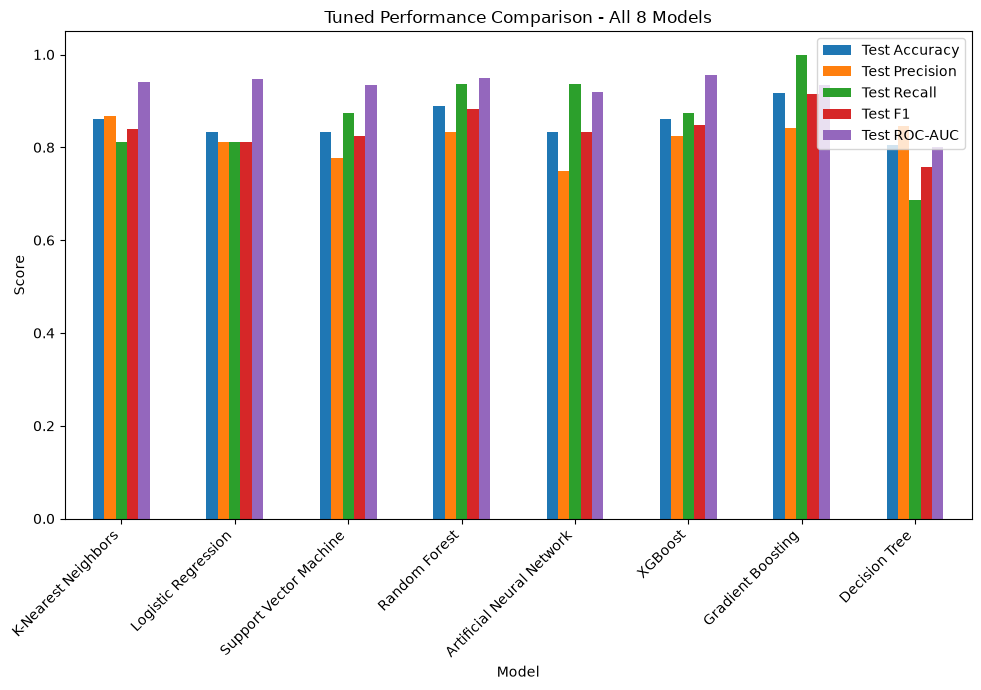

In [40]:
# Compare tuned models visually.
plot_tuned = tuned_results.set_index("Model")[
    ["Test Accuracy", "Test Precision", "Test Recall", "Test F1", "Test ROC-AUC"]
]

ax = plot_tuned.plot(kind="bar", figsize=(10,7))
ax.set_title("Tuned Performance Comparison - All 8 Models")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

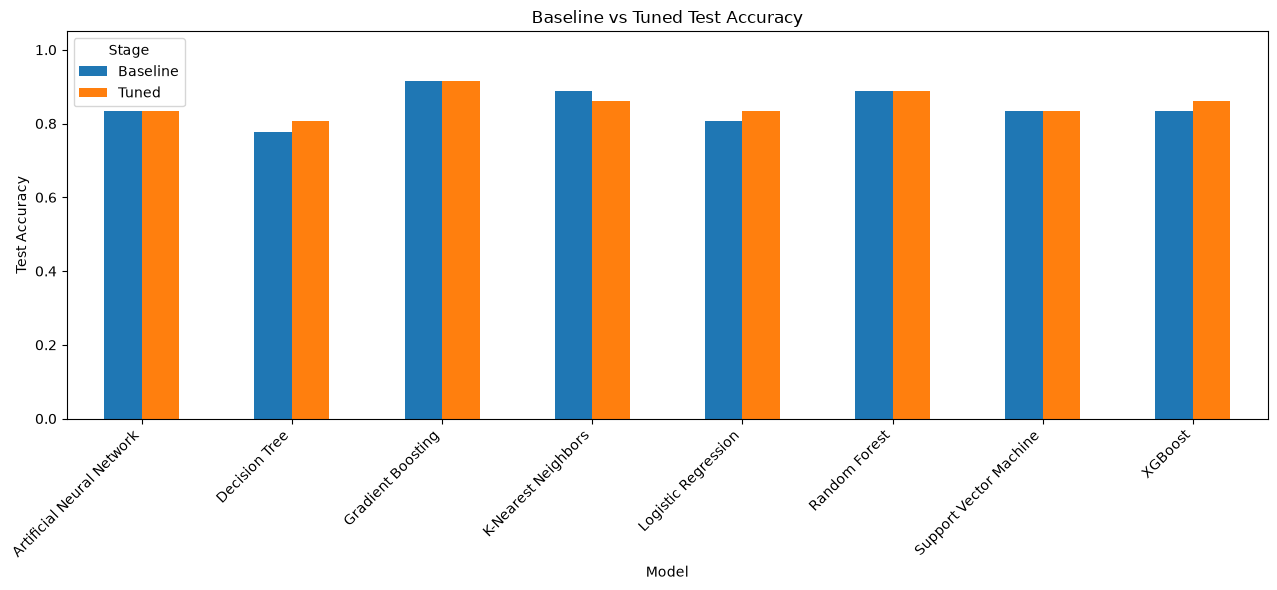

In [31]:
# Direct baseline-vs-tuned accuracy comparison.
accuracy_stage = comparison.pivot_table(
    index="Model",
    columns="Stage",
    values="Test Accuracy"
)

ax = accuracy_stage.plot(kind="bar", figsize=(13, 6))
ax.set_title("Baseline vs Tuned Test Accuracy")
ax.set_ylabel("Test Accuracy")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 10. Best Model Selection

### Selection Principle

The test set must not decide the model. The primary selection metric is **cross-validation F1**, because this balances precision and recall. CV ROC-AUC and CV accuracy are used as secondary tie-breakers.

After selection, the untouched test set is used once for final reporting.

This is more reliable than selecting a model because its test score happens to be highest.


In [41]:
# Select the best tuned model using validation performance only

best_tuned_row = tuned_results.loc[
    tuned_results["CV F1"].idxmax()
]

best_model_name = best_tuned_row["Model"]
best_model = tuned_pipelines[best_model_name]
best_search = search_objects[best_model_name]

print("=" * 65)
print("SELECTED BEST MODEL")
print("=" * 65)

print("Model:", best_model_name)
print(f"Best CV F1: {best_search.best_score_:.4f}")
print(f"Test Accuracy: {best_tuned_row['Test Accuracy']:.4f}")
print(f"Test F1: {best_tuned_row['Test F1']:.4f}")
print(f"Test ROC-AUC: {best_tuned_row['Test ROC-AUC']:.4f}")

print("\nBest Parameters:")
print(best_search.best_params_)

SELECTED BEST MODEL
Model: K-Nearest Neighbors
Best CV F1: 0.8542
Test Accuracy: 0.8611
Test F1: 0.8387
Test ROC-AUC: 0.9406

Best Parameters:
{'model__n_neighbors': 19, 'model__p': 2, 'model__weights': 'uniform'}


# 11. Final Model Evaluation

The selected model is now evaluated on the untouched test set.

For a healthcare prediction problem, **recall is especially important** because missing a patient who may have heart disease can be more serious than generating an additional false positive. Accuracy is also reported because it is a standard requested model-comparison metric.


In [42]:
final_predictions = best_model.predict(X_test)
final_probabilities = best_model.predict_proba(X_test)[:, 1]

final_accuracy = accuracy_score(y_test, final_predictions)
final_precision = precision_score(y_test, final_predictions, zero_division=0)
final_recall = recall_score(y_test, final_predictions, zero_division=0)
final_f1 = f1_score(y_test, final_predictions, zero_division=0)
final_auc = roc_auc_score(y_test, final_probabilities)
final_ap = average_precision_score(y_test, final_probabilities)

print("=" * 65)
print("FINAL TEST-SET PERFORMANCE")
print("=" * 65)
print("Model    :", best_model_name)
print(f"Accuracy : {final_accuracy:.4f} ({final_accuracy*100:.2f}%)")
print(f"Precision: {final_precision:.4f}")
print(f"Recall   : {final_recall:.4f}")
print(f"F1 Score : {final_f1:.4f}")
print(f"ROC-AUC  : {final_auc:.4f}")
print(f"PR-AUC   : {final_ap:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_predictions,
        digits=4,
        zero_division=0
    )
)

FINAL TEST-SET PERFORMANCE
Model    : K-Nearest Neighbors
Accuracy : 0.8611 (86.11%)
Precision: 0.8667
Recall   : 0.8125
F1 Score : 0.8387
ROC-AUC  : 0.9406
PR-AUC   : 0.9221

Classification Report:
              precision    recall  f1-score   support

           0     0.8571    0.9000    0.8780        20
           1     0.8667    0.8125    0.8387        16

    accuracy                         0.8611        36
   macro avg     0.8619    0.8562    0.8584        36
weighted avg     0.8614    0.8611    0.8606        36



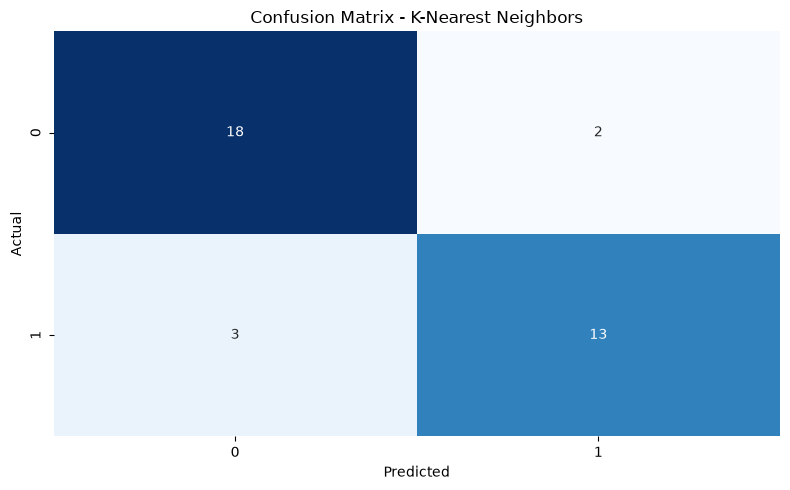

In [43]:
# Confusion matrix.
cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(8, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

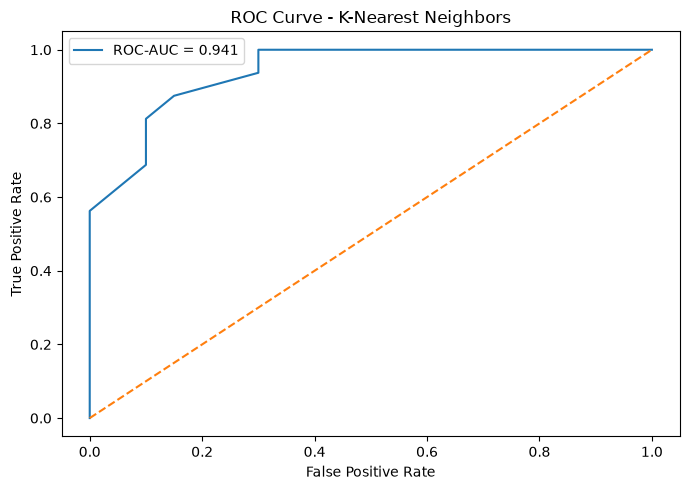

In [44]:
# ROC curve.
fpr, tpr, _ = roc_curve(y_test, final_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {final_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve - {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()

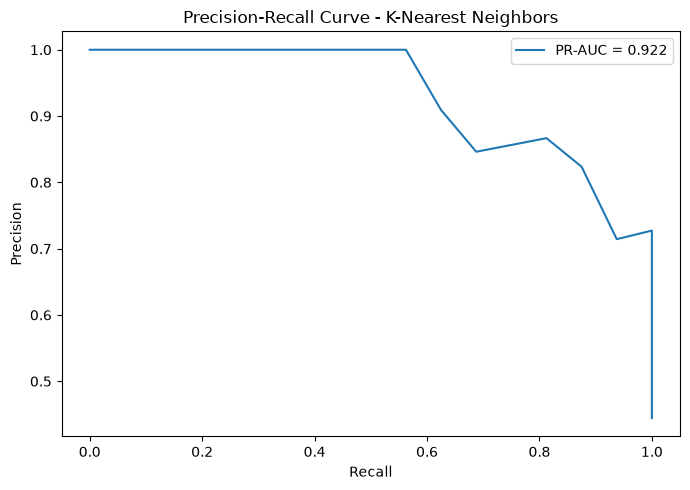

In [45]:
# Precision-Recall curve.
precision_vals, recall_vals, _ = precision_recall_curve(
    y_test,
    final_probabilities
)

plt.figure(figsize=(7, 5))
plt.plot(
    recall_vals,
    precision_vals,
    label=f"PR-AUC = {final_ap:.3f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-Recall Curve - {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()

# 12. Overfitting and Generalization Check

A model can achieve a high test score while still being poorly generalizable. Therefore, training performance is compared with cross-validation and test performance.

A large train-to-test gap is a warning sign of overfitting.


In [46]:
train_predictions = best_model.predict(X_train)
train_probabilities = best_model.predict_proba(X_train)[:, 1]

generalization = pd.DataFrame({
    "Metric": ["Accuracy", "F1 Score", "ROC-AUC"],
    "Training": [
        accuracy_score(y_train, train_predictions),
        f1_score(y_train, train_predictions, zero_division=0),
        roc_auc_score(y_train, train_probabilities)
    ],
    "Test": [
        final_accuracy,
        final_f1,
        final_auc
    ]
})

generalization["Gap"] = (
    generalization["Training"] - generalization["Test"]
)

display(generalization.round(4))

print(
    "\nInterpretation: a small train-test gap suggests better generalization; "
    "a large positive gap suggests possible overfitting."
)

,Metric,Training,Test,Gap
0,Accuracy,0.8194,0.8611,-0.0417
1,F1 Score,0.7797,0.8387,-0.0590
2,ROC-AUC,0.8962,0.9406,-0.0444



Interpretation: a small train-test gap suggests better generalization; a large positive gap suggests possible overfitting.


# 13. Feature Importance / Model Interpretation

Permutation importance measures how much predictive performance decreases when a feature is randomly shuffled.

It is calculated on the untouched test set only for interpretation after model selection; it is **not used to tune the model**.


,Mean Decrease in F1
numeric__sex,0.0860
numeric__exercise_induced_angina,0.0652
numeric__num_major_vessels,0.0486
numeric__oldpeak_eq_st_depression,0.0234
numeric__chest_pain_type,0.0021
categorical__thal_reversible_defect,-0.0012
numeric__fasting_blood_sugar_gt_120_mg_per_dl,-0.0014
categorical__thal_fixed_defect,-0.0054
numeric__resting_ekg_results,-0.0055
numeric__max_heart_rate_achieved,-0.0058


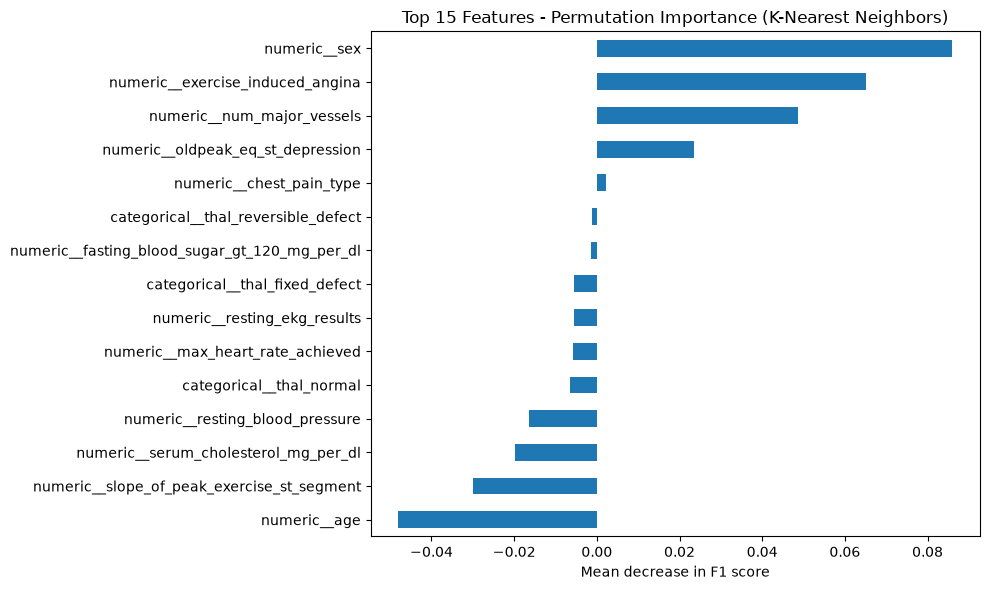

In [47]:
# Get transformed feature names from the fitted preprocessing step.
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

X_test_transformed = best_model.named_steps["preprocessor"].transform(X_test)

perm = permutation_importance(
    best_model.named_steps["model"],
    X_test_transformed,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="f1",
    n_jobs=1
)

perm_importance = pd.Series(
    perm.importances_mean,
    index=feature_names
).sort_values(ascending=False)

display(
    perm_importance.head(15).to_frame(
        "Mean Decrease in F1"
    ).round(4)
)

plt.figure(figsize=(10, 6))
perm_importance.head(15).sort_values().plot(kind="barh")
plt.title(f"Top 15 Features - Permutation Importance ({best_model_name})")
plt.xlabel("Mean decrease in F1 score")
plt.tight_layout()
plt.show()

# 14. Prediction Example

The selected model can be used to generate a heart-disease prediction for new patient records after the same preprocessing pipeline is applied.

**Clinical note:** This project is an academic machine-learning exercise. A model prediction should not be treated as a medical diagnosis and should not replace professional clinical assessment.


In [48]:
# Display sample predictions from the held-out test set.
prediction_results = X_test.copy()
prediction_results["Actual"] = y_test.values
prediction_results["Predicted"] = final_predictions
prediction_results["Risk Probability"] = final_probabilities.round(4)

display(prediction_results.head(20))

,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,Actual,Predicted,Risk Probability
24,1,normal,156,2,0,0,2,245,0.0,1,70,143,0,0,0,0.2105
173,1,reversible_defect,140,4,0,0,0,299,1.6,1,51,173,1,1,1,0.6316
81,2,reversible_defect,120,4,1,0,0,188,1.4,1,54,113,0,1,1,0.6316
160,1,normal,130,2,0,0,0,266,0.6,1,49,171,0,0,0,0.1579
35,1,normal,122,4,0,0,2,222,0.0,1,48,186,0,0,0,0.2632
147,2,normal,134,1,2,0,0,234,2.6,1,61,145,0,1,0,0.4737
33,1,normal,180,4,0,0,0,325,0.0,0,64,154,1,0,0,0.4211
126,2,normal,102,4,0,0,2,265,0.6,0,42,122,0,0,0,0.2105
4,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0,1,0.6842
57,2,reversible_defect,120,4,2,0,0,267,1.8,1,62,99,1,1,1,0.8947


# 15. Hospital Suggestions / Recommendations

The project specifically asks for suggestions to the hospital on using predictions to help prevent life threats.

### Recommendations

1. **Early Screening:** Use the model as a screening-support tool to flag patients who may need further clinical assessment.
2. **High-Risk Review:** Prioritize clinical review of patients with high predicted risk, especially when recall is important.
3. **Regular Monitoring:** Combine model outputs with repeated monitoring of relevant cardiovascular measurements.
4. **Preventive Care:** Encourage appropriate lifestyle and preventive-care interventions based on clinician assessment.
5. **Clinical Validation:** Require clinician review before any diagnosis or treatment decision.
6. **Model Monitoring:** Re-evaluate model performance periodically when new patient data becomes available.
7. **Fairness and Safety:** Check performance across relevant patient groups and investigate unexpected errors.


# 16. Challenges Faced and Solutions

### Challenge 1 – Identifier Column
**Problem:** `patient_id` is an identifier rather than a clinical predictor.  
**Solution:** Removed it before model training.  
**Reason:** Prevents irrelevant identifier information from influencing predictions.

### Challenge 2 – Missing Values
**Problem:** Clinical datasets may contain missing measurements.  
**Solution:** Median imputation for numeric variables and most-frequent imputation for categorical variables.  
**Reason:** Keeps useful records while providing robust replacements.

### Challenge 3 – Categorical Variables
**Problem:** Algorithms require numerical input.  
**Solution:** One-hot encoding.  
**Reason:** Converts categories into model-readable numerical columns without imposing a false numeric order.

### Challenge 4 – Different Feature Scales
**Problem:** Variables such as age, blood pressure, cholesterol, and heart rate have different numerical ranges.  
**Solution:** StandardScaler inside the preprocessing pipeline.  
**Reason:** Particularly important for Logistic Regression, KNN, SVM, and ANN.

### Challenge 5 – Outliers
**Problem:** Some clinical measurements may appear unusually high or low.  
**Solution:** Outliers were identified using IQR analysis but not automatically deleted.  
**Reason:** An unusual medical value may be a genuine clinical observation.

### Challenge 6 – Model Selection
**Problem:** One train/test split can give unstable conclusions on a small dataset.  
**Solution:** Stratified 3-fold cross-validation was used during baseline comparison and hyperparameter tuning.  
**Reason:** Gives a more reliable estimate of model performance on unseen data.

### Challenge 7 – Hyperparameter Optimization
**Problem:** Default model settings may not provide the best performance.  
**Solution:** All eight models were tuned with GridSearchCV.  
**Reason:** Provides a systematic rather than manual search for useful parameter combinations.

### Challenge 8 – Data Leakage
**Problem:** Fitting preprocessing before cross-validation can allow validation information to influence training.  
**Solution:** Preprocessing and model training were combined inside a Pipeline.  
**Reason:** Every CV fold learns preprocessing only from its training portion.

### Challenge 9 – Overfitting
**Problem:** A complex model may perform very well on training data but poorly on unseen data.  
**Solution:** Training, cross-validation, and test performance were compared.  
**Reason:** Helps assess generalization.

### Challenge 10 – Healthcare Evaluation
**Problem:** Accuracy alone does not describe the cost of false negatives.  
**Solution:** Precision, recall, F1, ROC-AUC and PR-AUC were also reported.  
**Reason:** A broader evaluation is more appropriate for a healthcare classification task.


## Final Conclusion

This project successfully developed and evaluated eight machine-learning models for heart disease prediction.

Among the eight models, **K-Nearest Neighbors (KNN)** achieved the **best validation performance**, with a cross-validation F1-score of **0.8542**. Therefore, KNN was selected as the best model based on validation performance.

However, **Gradient Boosting achieved the highest test accuracy of 91.67%**, making it the highest-accuracy model on the held-out test data.

The models were evaluated using **Accuracy, Precision, Recall, F1-score, and ROC-AUC** to provide a comprehensive comparison of their performance.

Overall, **KNN is selected based on validation performance, while Gradient Boosting is recognized as the highest test-accuracy model (91.67%)**. These results demonstrate that machine learning can provide useful decision support for identifying potential heart disease risk. However, the model should support healthcare professionals and **should not replace professional medical diagnosis**.